# 01. Preprocess InHARD-DT and InHARD (real data only)

Parses every segmented BVH clip of both datasets with the vectorised parser in `picda/bvh.py`, resamples to 30 Hz and writes one `.npz` per clip (all 59 joints, world coordinates in cm) to `data/processed_v2/`, plus `index.csv`, `joint_names.json` and the subject-disjoint `splits.json`.

Nothing here is synthetic. If a file is missing the code raises.

**What to send back after running:** the printed outputs of sections 1, 2 and 3 (parser checks, status counts, class/subject table) and the two figures.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from picda import config as C
from picda.bvh import read_bvh, forward_kinematics
from picda.preprocess import build_all
from picda.data import load_index, make_splits, load_raw
from picda.skeleton import joint_names, parent_indices, selection_indices

FIG_DIR = C.OUTPUT_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
print('DT raw dir exists  :', C.RAW_DT_DIR.exists(), C.RAW_DT_DIR)
print('Real raw dir exists:', C.RAW_REAL_DIR.exists(), C.RAW_REAL_DIR)

DT raw dir exists  : True /home/g0amer/Desktop/thesis/04_Cross_Modal_Digital_Twin/data/inhard_dt/raw/InHARD-DT/Segmented/Skeleton
Real raw dir exists: True /home/g0amer/Desktop/thesis/04_Cross_Modal_Digital_Twin/data/inhard/raw/Segmented/SkletonSegmented


## 1. Parser checks

Three independent checks on one clip per domain:
1. bone lengths must be constant over time (rigid skeleton), so their coefficient of variation should be ~0;
2. the hierarchy must be identical in both datasets;
3. if `bvhio` is installed, our forward kinematics must match it (max absolute difference in cm).

In [2]:
samples = {}
for domain, root in [('dt', C.RAW_DT_DIR), ('real', C.RAW_REAL_DIR)]:
    f = sorted(root.rglob('*.bvh'))[0]
    clip = read_bvh(f)
    W = forward_kinematics(clip)
    lens = np.stack([np.linalg.norm(W[:, j] - W[:, p], axis=-1)
                     for j, p in enumerate(clip.parents) if p >= 0], axis=1)
    cv = lens.std(0) / (lens.mean(0) + 1e-9)
    print(f'[{domain}] {f.name}: joints={len(clip.names)}, frames={clip.motion.shape[0]} '
          f'(declared {clip.declared_frames}), fps={clip.fps:.2f}, max bone-length CV={cv.max():.2e}')
    print(f'        Hips height frame0 = {W[0, 0, 1]:.1f} cm, hips rotation channels frame0 = {clip.motion[0, 3:6].round(1)}')
    samples[domain] = (f, clip, W)

print('Identical hierarchy in both datasets:', samples['dt'][1].names == samples['real'][1].names)

try:
    import bvhio
    for domain, (f, clip, W) in samples.items():
        root = bvhio.readAsHierarchy(str(f))
        joints = [item[0] for item in root.layout()]
        assert [j.Name for j in joints] == clip.names, 'joint order differs from bvhio'
        worst = 0.0
        for fr in [0, len(W) // 2, len(W) - 1]:
            root.loadKeyframe(fr)
            ref = np.array([[j.PositionWorld.x, j.PositionWorld.y, j.PositionWorld.z] for j in joints])
            worst = max(worst, np.abs(ref - W[fr]).max())
        print(f'[{domain}] max |ours - bvhio| over 3 frames = {worst:.4f} cm')
except ImportError:
    print('bvhio not installed: skipping the cross-check (pip install bvhio to enable it).')

[dt] A00_LMVR_10_Fabrice_Manip_0143.19_0145.94.bvh: joints=59, frames=327 (declared 327), fps=119.06, max bone-length CV=1.12e-02
        Hips height frame0 = 97.2 cm, hips rotation channels frame0 = [67.1 -5.   0.6]
[real] P01_R01_0013.84_0018.88.bvh: joints=59, frames=600 (declared 600), fps=119.03, max bone-length CV=2.79e-03
        Hips height frame0 = 94.2 cm, hips rotation channels frame0 = [-98.3  -2.   -3.4]
Identical hierarchy in both datasets: True
bvhio not installed: skipping the cross-check (pip install bvhio to enable it).


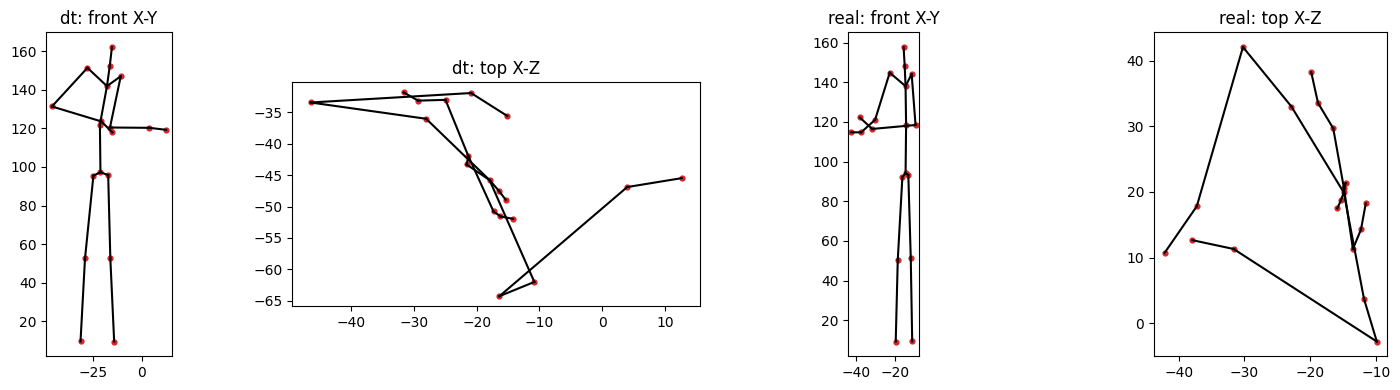

In [3]:
# Visual check of the 19-joint body set on frame 0 (front view X-Y and top view X-Z)
names59 = samples['dt'][1].names
sel = selection_indices(names59, 'body19')
parents = parent_indices('body19')
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for k, domain in enumerate(['dt', 'real']):
    P = samples[domain][2][0, sel]
    for col, (a, b, title) in enumerate([(0, 1, 'front X-Y'), (0, 2, 'top X-Z')]):
        ax = axes[2 * k + col]
        for j, p in enumerate(parents):
            if p >= 0:
                ax.plot([P[j, a], P[p, a]], [P[j, b], P[p, b]], 'k-')
        ax.scatter(P[:, a], P[:, b], c='tab:red', s=12)
        ax.set_title(f'{domain}: {title}')
        ax.set_aspect('equal')
plt.tight_layout()
plt.show()

## 2. Process all clips

Resumable: existing `.npz` files are kept unless `overwrite=True`. "No action" clips of InHARD are skipped on purpose (no counterpart in InHARD-DT).

In [4]:
index_all = build_all(overwrite=False)
status = index_all.status.where(index_all.status.isin(['ok']), index_all.status.str.split(':').str[0])
print(pd.crosstab(index_all.domain, status))
errors = index_all[index_all.status.str.startswith('error')]
if len(errors):
    print(errors[['clip_id', 'status']].head(20).to_string())

dt:   0%|          | 0/4696 [00:00<?, ?it/s]

real:   0%|          | 0/5303 [00:00<?, ?it/s]

status  excluded class 'No action'    ok
domain                                  
dt                               0  4696
real                           500  4803


## 3. Dataset summary and subject-disjoint splits

In [5]:
index = load_index()
counts = pd.crosstab(index.class_folder, index.domain)
counts['dt_share_%'] = (100 * counts['dt'] / counts['dt'].sum()).round(1)
counts['real_share_%'] = (100 * counts['real'] / counts['real'].sum()).round(1)
print(counts.to_string())
print()
print(index.groupby('domain').agg(clips=('clip_id', 'size'), subjects=('subject', 'nunique'),
                                  sessions=('session', 'nunique'), mean_dur_s=('duration_s', 'mean'),
                                  median_frames30=('n_frames', 'median')).to_string())
print()
print(index.groupby(['domain', 'subject']).size().unstack(0).to_string())

splits = make_splits(index, n_folds_real=4, n_folds_dt=4)
print()
for k, v in splits.items():
    print(k, v)

domain                   dt  real  dt_share_%  real_share_%
class_folder                                               
Assemble system         518  1378        11.0          28.7
Consult sheets          190   132         4.0           2.7
Picking in front        310   456         6.6           9.5
Picking left            491   641        10.5          13.3
Put down component      352   385         7.5           8.0
Put down measuring rod  207    74         4.4           1.5
Put down screwdriver    266   416         5.7           8.7
Put down subsystem      251    77         5.3           1.6
Take component          410   485         8.7          10.1
Take measuring rod      364    76         7.8           1.6
Take screwdriver        533   420        11.4           8.7
Take subsystem          335    39         7.1           0.8
Turn sheets             469   224        10.0           4.7

        clips  subjects  sessions  mean_dur_s  median_frames30
domain                              

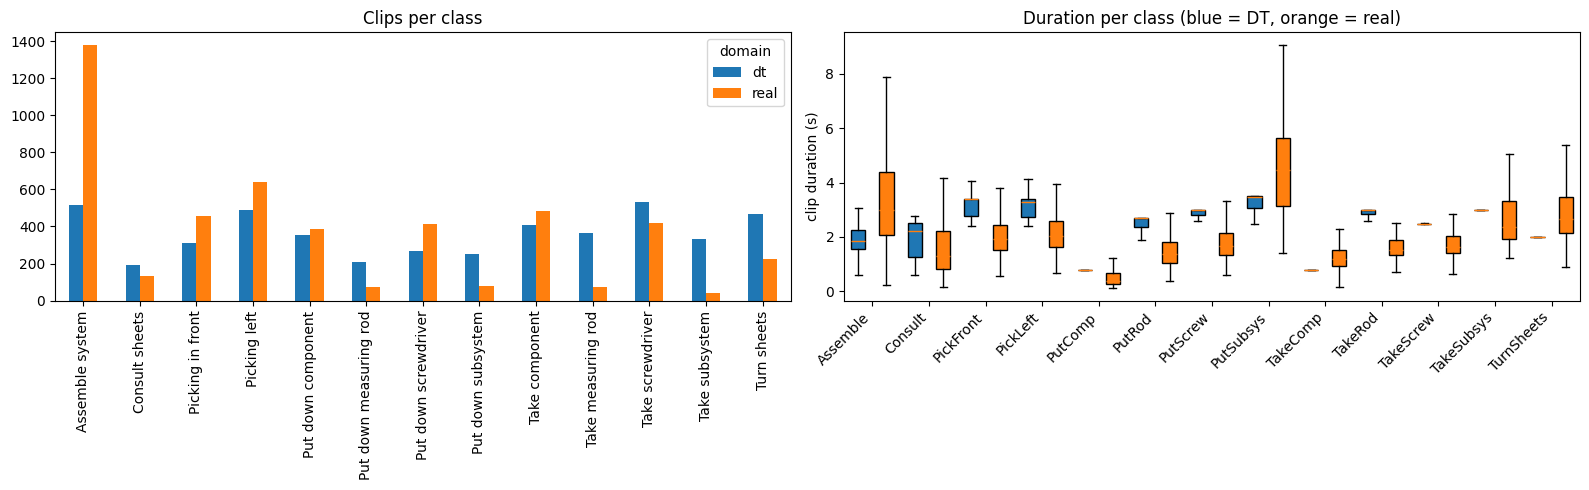

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
counts[['dt', 'real']].plot.bar(ax=axes[0])
axes[0].set_title('Clips per class')
axes[0].set_xlabel('')
order = C.CLASS_NAMES
data, labels, colors = [], [], []
for c in order:
    for d, col in [('dt', 'tab:blue'), ('real', 'tab:orange')]:
        data.append(index.loc[(index.class_folder == c) & (index.domain == d), 'duration_s'].values)
        colors.append(col)
bp = axes[1].boxplot(data, patch_artist=True, showfliers=False)
for patch, col in zip(bp['boxes'], colors):
    patch.set_facecolor(col)
axes[1].set_xticks(np.arange(1.5, 2 * len(order), 2))
axes[1].set_xticklabels(C.SHORT_NAMES, rotation=45, ha='right')
axes[1].set_ylabel('clip duration (s)')
axes[1].set_title('Duration per class (blue = DT, orange = real)')
plt.tight_layout()
plt.savefig(FIG_DIR / 'dataset_counts_durations.png', dpi=200)
plt.show()